# 03 · Listing segments (K-Means clustering)

**Question:** what *kinds* of places make up Istanbul's Airbnb market?

We cluster listings on **what they are and where they are**, without using the price. Afterwards we check how price differs between segments. If segments built without price still separate prices, that confirms the features matter.

Output: a `segment` and a human name for every listing (used in the slides and as a label in the app).

In [17]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("..").resolve()          # repo root (notebooks/ is one level down)
sys.path.insert(0, str(ROOT))
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIGS = ROOT / "reports" / "figures"
for p in (PROCESSED, MODELS, FIGS):
    p.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
SEED = 42
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [18]:
df = pd.read_parquet(PROCESSED / "listings_priced.parquet")
# drop segment columns from an earlier run so re-running this notebook is safe
df = df.drop(columns=[c for c in df.columns if c.startswith(("segment",))])

SEG_FEATURES = ["accommodates", "bedrooms", "bathrooms_n", "n_amenities", "is_shared_bath",
                "has_kitchen", "has_sea_view", "has_workspace", "is_superhost", "host_listings",
                "is_asia", "dist_sultanahmet_m", "dist_station_m", "restaurants_500m"]
Xs = df[SEG_FEATURES].copy()
# One-hot stay type so hotels / homes / rooms can separate
Xs = Xs.join(pd.get_dummies(df["stay_type"], prefix="st", dtype=int))
# Distances and counts are very skewed -> log them
for c in ["dist_sultanahmet_m", "dist_station_m", "restaurants_500m", "host_listings"]:
    Xs[c] = np.log1p(Xs[c])
scaler = StandardScaler().fit(Xs)
Z = scaler.transform(Xs)
Z.shape

(24190, 19)

## Version A: segments with the stay type

### Choose k: elbow + silhouette

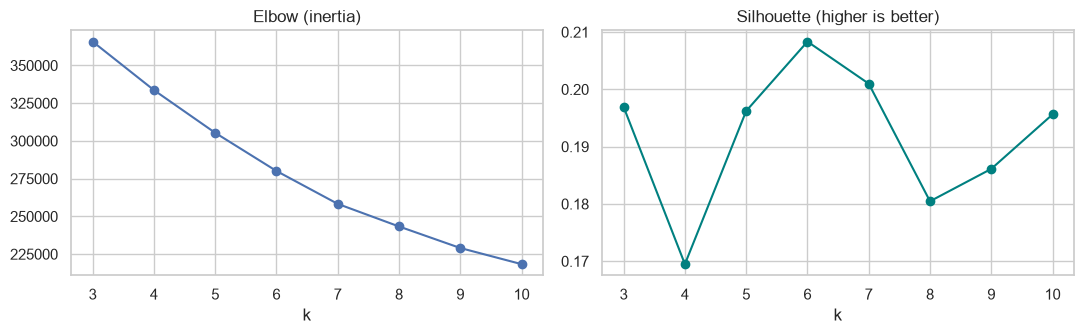

,k,silhouette
0,3,0.197
1,4,0.169
2,5,0.196
3,6,0.208
4,7,0.201
5,8,0.180
6,9,0.186
7,10,0.196


In [19]:
ks = range(3, 11)
inertia, sil = [], []
rng = np.random.default_rng(SEED)
sample = rng.choice(len(Z), size=min(8000, len(Z)), replace=False)   # silhouette is slow on all rows
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z[sample], km.labels_[sample]))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(list(ks), inertia, "o-"); ax[0].set(title="Elbow (inertia)", xlabel="k")
ax[1].plot(list(ks), sil, "o-", color="teal"); ax[1].set(title="Silhouette (higher is better)", xlabel="k")
plt.tight_layout(); plt.savefig(FIGS / "kmeans_choose_k.png", dpi=120); plt.show()
pd.DataFrame({"k": list(ks), "silhouette": np.round(sil, 3)})

**Pick k:** _look for the bend in the elbow and a high silhouette. 5–7 segments are also easy to explain on a slide._

In [20]:
K = 6   # <- set from the charts above
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z)
df["segment"] = km.labels_
df["segment"].value_counts().sort_index()

segment
0    10306
1     3837
2     5175
3     3008
4      161
5     1703
Name: count, dtype: int64

## Profile each segment

In [21]:
profile = df.groupby("segment").agg(
    listings=("id", "size"),
    median_price=("price", "median"),
    guests=("accommodates", "median"),
    bedrooms=("bedrooms", "median"),
    amenities=("n_amenities", "median"),
    km_to_sultanahmet=("dist_sultanahmet_m", lambda s: s.median() / 1000),
    asia_share=("is_asia", "mean"),
    sea_view=("has_sea_view", "mean"),
    superhost=("is_superhost", "mean"),
    host_listings=("host_listings", "median"),
    top_stay_type=("stay_type", lambda s: s.mode()[0]),
    top_district=("neighbourhood_cleansed", lambda s: s.mode()[0]),
).round(2)
profile

,listings,median_price,guests,bedrooms,amenities,km_to_sultanahmet,asia_share,sea_view,superhost,host_listings,top_stay_type,top_district
segment,,,,,,,,,,,,
0,10306,4555.50,4.0,1.0,36.0,3.19,0.10,0.08,0.37,8.0,Entire home,Beyoglu
1,3837,3213.03,2.0,1.0,23.0,3.09,0.14,0.04,0.12,8.0,Hotel room,Fatih
2,5175,3791.00,4.0,1.0,26.0,14.80,0.31,0.09,0.11,3.0,Entire home,Esenyurt
3,3008,1472.74,2.0,1.0,16.0,5.44,0.31,0.05,0.09,2.0,Private room,Sisli
4,161,2375.00,2.0,0.0,15.0,3.40,0.25,0.02,0.09,5.0,Hostel / shared,Fatih
5,1703,4347.00,3.0,1.0,37.0,4.23,0.13,0.07,0.32,11.0,Serviced apt,Beyoglu


In [22]:
# Name each segment from the profile above (edit these!)
SEGMENT_NAMES = {
    0: "Central full flats",        # 10.3k · ₺4,556 · Beyoğlu · 3 km from Sultanahmet · most amenities, 37% Superhosts
    1: "Old-city hotel rooms",      # 3.8k · ₺3,213 · Fatih
    2: "Suburban family homes",     # 5.2k · ₺3,791 · Esenyurt · ~15 km out, 31% on the Asian side
    3: "Budget private rooms",      # 3.0k · ₺1,473 · fewest amenities
    4: "Hostels & shared",          # 161 listings
    5: "Pro-hosted serviced apts",  # 1.7k · ₺4,347 · hosts with ~11 listings
}
df["segment_name"] = df["segment"].map(SEGMENT_NAMES)
SEGMENT_NAMES_V1 = SEGMENT_NAMES

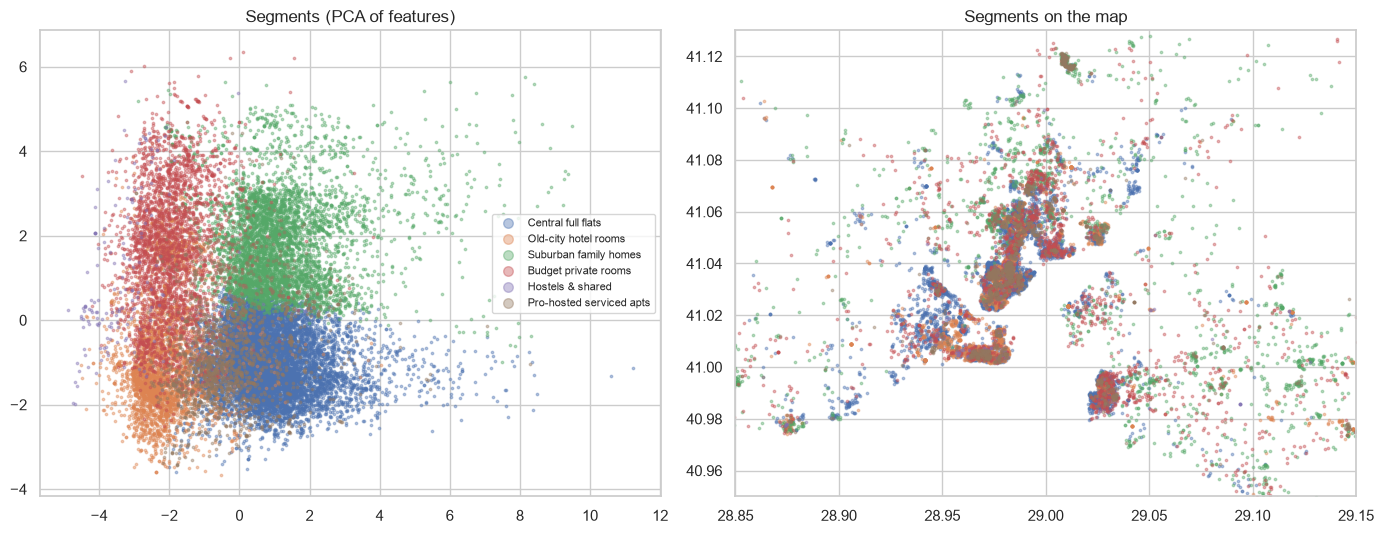

In [23]:
# Picture: segments on a 2-D PCA projection and on the map
xy = PCA(2, random_state=SEED).fit_transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for s in range(K):
    m = df["segment"] == s
    ax[0].scatter(xy[m, 0], xy[m, 1], s=3, alpha=.4, label=SEGMENT_NAMES[s])
    ax[1].scatter(df.loc[m, "longitude"], df.loc[m, "latitude"], s=3, alpha=.4)
ax[0].set(title="Segments (PCA of features)"); ax[0].legend(markerscale=4, fontsize=8)
ax[1].set(title="Segments on the map", xlim=(28.85, 29.15), ylim=(40.95, 41.13))
plt.tight_layout(); plt.savefig(FIGS / "segments.png", dpi=120); plt.show()

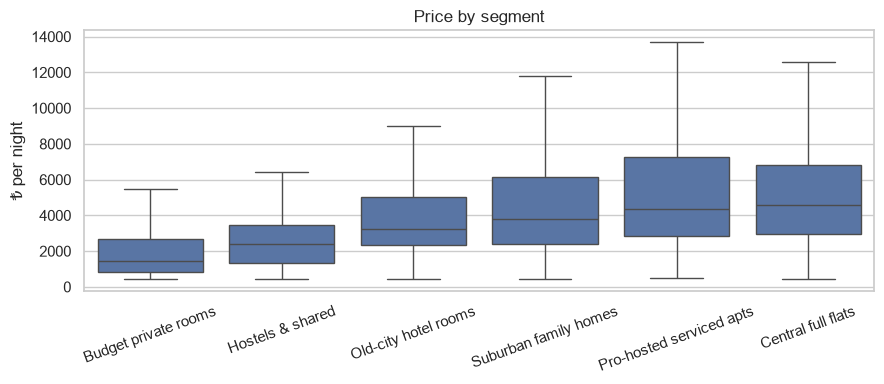

In [24]:
# Price was NOT used to build the segments. Do they still separate prices?
fig, ax = plt.subplots(figsize=(9, 4))
order = df.groupby("segment_name")["price"].median().sort_values().index
sns.boxplot(data=df, x="segment_name", y="price", order=order, showfliers=False, ax=ax)
ax.set(title="Price by segment", xlabel="", ylabel="₺ per night"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(FIGS / "price_by_segment.png", dpi=120); plt.show()

**What I see:** _…_ (version A mostly rediscovers the stay types, because they were one-hot inputs)

In [25]:
# Keep version A for the comparison; version B below becomes the main `segment`
df = df.rename(columns={"segment": "segment_v1", "segment_name": "segment_name_v1"})
sil_v1 = silhouette_score(Z[sample], km.labels_[sample])
km_v1 = km

## Version B: segments without the stay type

Stay type is something the guest already picks in the app, so segments that just repeat it add little.
Here we drop the stay-type columns and let K-Means group listings only on **size, amenities, host and location**.

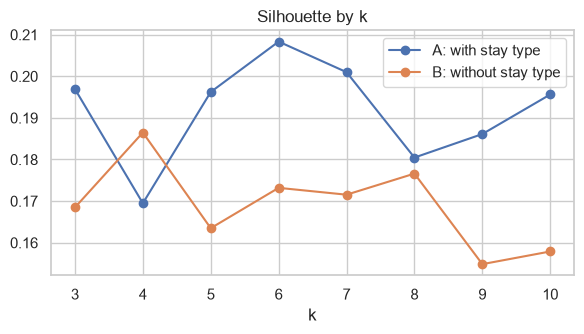

,k,A_with_type,B_without_type
0,3,0.197,0.168
1,4,0.169,0.186
2,5,0.196,0.163
3,6,0.208,0.173
4,7,0.201,0.172
5,8,0.180,0.177
6,9,0.186,0.155
7,10,0.196,0.158


In [26]:
Xb = df[SEG_FEATURES].copy()
for c in ["dist_sultanahmet_m", "dist_station_m", "restaurants_500m", "host_listings"]:
    Xb[c] = np.log1p(Xb[c])
scaler_b = StandardScaler().fit(Xb)
Zb = scaler_b.transform(Xb)

sil_b = []
for k in ks:
    kmb = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Zb)
    sil_b.append(silhouette_score(Zb[sample], kmb.labels_[sample]))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(list(ks), sil, "o-", label="A: with stay type")
ax.plot(list(ks), sil_b, "o-", label="B: without stay type")
ax.set(title="Silhouette by k", xlabel="k"); ax.legend()
plt.tight_layout(); plt.savefig(FIGS / "kmeans_choose_k_b.png", dpi=120); plt.show()
pd.DataFrame({"k": list(ks), "A_with_type": np.round(sil, 3), "B_without_type": np.round(sil_b, 3)})

In [27]:
K_B = 6   # <- set from the chart above
km = KMeans(n_clusters=K_B, n_init=20, random_state=SEED).fit(Zb)
df["segment"] = km.labels_
profile_b = df.groupby("segment").agg(
    listings=("id", "size"),
    median_price=("price", "median"),
    guests=("accommodates", "median"),
    amenities=("n_amenities", "median"),
    km_to_sultanahmet=("dist_sultanahmet_m", lambda s: s.median() / 1000),
    asia_share=("is_asia", "mean"),
    sea_view=("has_sea_view", "mean"),
    shared_bath=("is_shared_bath", "mean"),
    host_listings=("host_listings", "median"),
    top_stay_type=("stay_type", lambda s: s.mode()[0]),
    top_district=("neighbourhood_cleansed", lambda s: s.mode()[0]),
).round(2)
profile_b

,listings,median_price,guests,amenities,km_to_sultanahmet,asia_share,sea_view,shared_bath,host_listings,top_stay_type,top_district
segment,,,,,,,,,,,
0,4426,5211.00,4.0,40.0,3.20,0.10,0.00,0.00,10.0,Entire home,Beyoglu
1,5697,3301.99,3.0,21.0,14.98,0.34,0.01,0.00,4.0,Entire home,Esenyurt
2,9502,3344.00,3.0,27.0,3.18,0.09,0.00,0.00,7.0,Entire home,Beyoglu
3,1585,5159.33,4.0,46.0,4.12,0.22,1.00,0.04,5.0,Entire home,Beyoglu
4,1804,1476.53,2.0,18.0,5.22,0.33,0.02,1.00,2.0,Private room,Fatih
5,1176,10189.08,8.0,38.0,4.98,0.12,0.07,0.03,7.0,Entire home,Beyoglu


In [28]:
# Name the segments from their profile. Rules (not hard-coded numbers) because K-Means
# can number the clusters differently on another machine. Check the result and edit if needed.
def name_segment(r):
    if r["sea_view"] > 0.5:         return "Sea-view stays"
    if r["shared_bath"] > 0.5:      return "Shared-bath budget rooms"
    if r["guests"] >= 7:            return "Large group homes"
    if r["km_to_sultanahmet"] > 10: return "Outer-district homes"
    return None

SEGMENT_NAMES = {s: name_segment(r) for s, r in profile_b.iterrows()}
# the remaining central clusters: split by amenities
rest = profile_b.loc[[s for s, n in SEGMENT_NAMES.items() if n is None]].sort_values("amenities", ascending=False)
labels = ["Central well-equipped flats", "Central standard stays", "Central stays (other)"]
for i, s in enumerate(rest.index):
    SEGMENT_NAMES[s] = labels[min(i, len(labels) - 1)]
df["segment_name"] = df["segment"].map(SEGMENT_NAMES)
profile_b.assign(name=pd.Series(SEGMENT_NAMES))[["name", "listings", "median_price", "guests", "sea_view", "shared_bath", "km_to_sultanahmet"]]

,name,listings,median_price,guests,sea_view,shared_bath,km_to_sultanahmet
segment,,,,,,,
0,Central well-equipped flats,4426,5211.00,4.0,0.00,0.00,3.20
1,Outer-district homes,5697,3301.99,3.0,0.01,0.00,14.98
2,Central standard stays,9502,3344.00,3.0,0.00,0.00,3.18
3,Sea-view stays,1585,5159.33,4.0,1.00,0.04,4.12
4,Shared-bath budget rooms,1804,1476.53,2.0,0.02,1.00,5.22
5,Large group homes,1176,10189.08,8.0,0.07,0.03,4.98


In [29]:
# Does version B cut across stay types? (rows: new segments, share of each stay type)
pd.crosstab(df["segment_name"], df["stay_type"], normalize="index").round(2)

stay_type,Entire home,Hostel / shared,Hotel room,Private room,Serviced apt
segment_name,,,,,
Central standard stays,0.59,0.00,0.25,0.08,0.08
Central well-equipped flats,0.78,0.00,0.08,0.04,0.10
Large group homes,0.84,0.00,0.07,0.02,0.07
Outer-district homes,0.70,0.00,0.14,0.12,0.04
Sea-view stays,0.76,0.00,0.09,0.07,0.07
Shared-bath budget rooms,0.00,0.08,0.17,0.72,0.02


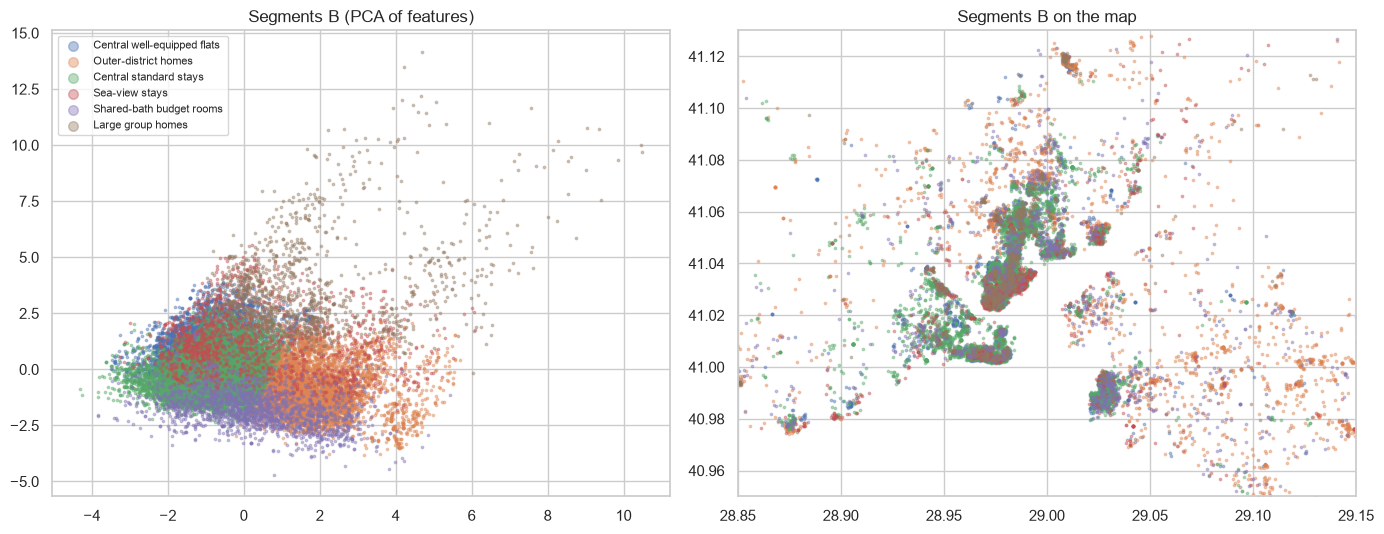

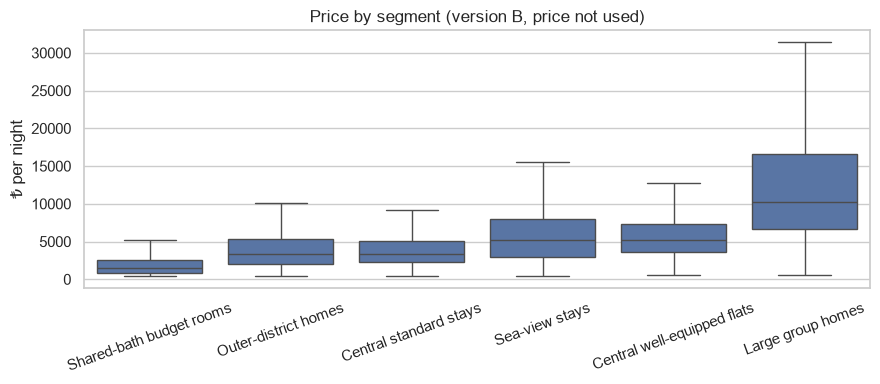

In [30]:
xy = PCA(2, random_state=SEED).fit_transform(Zb)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for s in range(K_B):
    m = df["segment"] == s
    ax[0].scatter(xy[m, 0], xy[m, 1], s=3, alpha=.4, label=SEGMENT_NAMES[s])
    ax[1].scatter(df.loc[m, "longitude"], df.loc[m, "latitude"], s=3, alpha=.4)
ax[0].set(title="Segments B (PCA of features)"); ax[0].legend(markerscale=4, fontsize=8)
ax[1].set(title="Segments B on the map", xlim=(28.85, 29.15), ylim=(40.95, 41.13))
plt.tight_layout(); plt.savefig(FIGS / "segments_b.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
order = df.groupby("segment_name")["price"].median().sort_values().index
sns.boxplot(data=df, x="segment_name", y="price", order=order, showfliers=False, ax=ax)
ax.set(title="Price by segment (version B, price not used)", xlabel="", ylabel="₺ per night"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(FIGS / "price_by_segment_b.png", dpi=120); plt.show()

In [31]:
# A vs B side by side
sil_b6 = silhouette_score(Zb[sample], km.labels_[sample])
pd.DataFrame({
    "silhouette": [sil_v1, sil_b6],
    "price spread between segments (max/min median)": [
        df.groupby("segment_name_v1")["price"].median().pipe(lambda s: s.max() / s.min()),
        df.groupby("segment_name")["price"].median().pipe(lambda s: s.max() / s.min())],
    "uses stay type": ["yes", "no"],
}, index=["A: with stay type", "B: without stay type"]).round(3)

,silhouette,price spread between segments (max/min median),uses stay type
A: with stay type,0.208,3.093,yes
B: without stay type,0.174,6.901,no


**What I see:** _… (B scores a bit lower on silhouette but finds groups the stay type can't show: sea views, big group homes, shared bathrooms) → the app uses B._

In [32]:
joblib.dump({"scaler": scaler_b, "kmeans": km, "features": list(Xb.columns), "names": SEGMENT_NAMES,
             "version_a": {"scaler": scaler, "kmeans": km_v1, "names": SEGMENT_NAMES_V1}},
            MODELS / "segments.joblib")
df.to_parquet(PROCESSED / "listings_priced.parquet", index=False)
print("saved segments (B is the main `segment_name`, A kept as `segment_name_v1`)")

saved segments (B is the main `segment_name`, A kept as `segment_name_v1`)
